# 0. Mục tiêu Tuần 3

Notebook tích hợp phần việc Tuần 3 của Nhân (Person 4): kế thừa nguyên trạng ba mô hình do Lợi, Trí và Danh xây dựng; chuẩn hóa cách đọc kết quả Cross-Validation; tạo learning curves; và xuất cấu hình siêu tham số tốt nhất. Mọi phép fit, tuning, so sánh và learning curve trong notebook chỉ dùng tập Train.

**Acceptance provenance (2026-11-05).** Recovered from local commit `2f94d03`. Code and original narrative are preserved except outputs now go to an isolated temporary directory, preventing historical artifact replacement. Current outputs are a reproduction, not the original execution.

**Default Logistic convergence:** a separate acceptance check with warnings enabled found all five folds reached max_iter=100 and emitted ConvergenceWarning (mean Macro-F1 0.6994773). The inherited warning filter below hides this warning; the default baseline is not fully converged. Historical 0.6990 remains a distinct recorded run; the precise cause of the numerical difference is not established.
**Methodological limit:** preprocessing, including supervised MI selection, was fitted once on the whole training split before CV. These are conditional CV scores with potential validation-fold leakage, not unbiased end-to-end pipeline estimates. Held-out data are not loaded here. Fold-local pipeline CV remains future work; the magnitude of bias is unknown.
The diagnostic gap cutoffs below are descriptive heuristics, not statistical tests.

# 1. Môi trường và khả năng tái lập

In [1]:
from pathlib import Path
import tempfile
REPRO_DIR = Path(tempfile.mkdtemp(prefix="btl_week3_reproduction_"))
import json
import platform
import sys
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, learning_curve
from sklearn.svm import SVC

CURRENT_DIR = Path.cwd().resolve()
REPO_ROOT = CURRENT_DIR if (CURRENT_DIR / 'src').exists() else CURRENT_DIR.parent
if not (REPO_ROOT / 'src').exists():
    raise RuntimeError('Không xác định được thư mục gốc của repository.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.tuning import make_cv_splitter

RANDOM_STATE = 42
PRIMARY_SCORING = 'f1_macro'
print({
    'repository': str(REPO_ROOT),
    'python': platform.python_version(),
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'primary_scoring': PRIMARY_SCORING,
})

{'repository': 'E:\\Downloads\\BTL_ML_acceptance_20261105\\baseline', 'python': '3.13.0', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'primary_scoring': 'f1_macro'}


# 2. Nạp dữ liệu Train

Đầu vào là ma trận 32 đặc trưng đã được pipeline Tuần 2 mã hóa và scale. Notebook kiểm tra tính tương thích của dữ liệu trước khi chạy mô hình.

In [2]:
X_train = pd.read_parquet(REPO_ROOT / 'data/processed/X_train.parquet')
y_train_frame = pd.read_parquet(REPO_ROOT / 'data/processed/y_train.parquet')
y_train = y_train_frame.iloc[:, 0]

assert len(X_train) == len(y_train), 'Số dòng X_train và y_train không khớp.'
assert X_train.index.equals(y_train_frame.index), 'Index X_train và y_train không khớp.'
assert X_train.select_dtypes(exclude=[np.number]).shape[1] == 0, 'X_train còn cột không phải số.'
assert not X_train.isna().any().any(), 'X_train chứa NaN.'
assert np.isfinite(X_train.to_numpy(dtype=float)).all(), 'X_train chứa +/-inf.'
assert not y_train.isna().any(), 'y_train chứa NaN.'
assert set(y_train.unique()) == {'no', 'yes'}, 'Nhãn mục tiêu không đúng kỳ vọng.'

data_summary = pd.DataFrame({
    'Thuộc tính': ['Số mẫu Train', 'Số đặc trưng', 'Nhãn no', 'Nhãn yes', 'NaN ở X', 'Inf ở X'],
    'Giá trị': [len(X_train), X_train.shape[1], int((y_train == 'no').sum()), int((y_train == 'yes').sum()), int(X_train.isna().sum().sum()), int(np.isinf(X_train.to_numpy(dtype=float)).sum())],
})
data_summary

,Thuộc tính,Giá trị
0,Số mẫu Train,8929
1,Số đặc trưng,32
2,Nhãn no,4698
3,Nhãn yes,4231
4,NaN ở X,0
5,Inf ở X,0


# 3. Quy ước không sử dụng Test trong Week 3

Hai tệp X_test và y_test được giữ kín cho đánh giá held-out ở Tuần 4. Notebook này không nạp, fit, score, so sánh hay lựa chọn mô hình bằng hai tệp đó.

# 4. Cross-Validation chung

Ba nhóm mô hình cùng dùng StratifiedKFold 5 folds, shuffle=True, random_state=42. Đây là cấu hình do src/tuning.py cung cấp.

In [3]:
cv = make_cv_splitter(
    task_type='classification',
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


# 5. Chỉ số đánh giá chính

PRIMARY_SCORING = f1_macro. Chỉ số này lấy trung bình F1 của hai lớp, phù hợp với quy ước đã dùng trong cả ba module của đồng đội và không để lớp đông hơn quyết định toàn bộ kết quả.

# 6–9. Baseline và ba mô hình kế thừa

- Lợi: Dummy most-frequent và Logistic Regression; artifact models/best_linear_model.pkl.
- Trí: Random Forest; artifact models/best_tree_model.pkl; estimator có feature_importances_.
- Danh: SVC kernel RBF; artifact models/best_nonlinear_model.pkl.

Notebook nạp estimator đã lưu và chỉ xây dựng lại các cấu hình default đúng như module của từng người để đánh giá trên cùng folds. Logic tuning và search space vẫn nằm trong các module đồng đội.

In [4]:
artifact_paths = {
    'linear': REPO_ROOT / 'models/best_linear_model.pkl',
    'tree': REPO_ROOT / 'models/best_tree_model.pkl',
    'nonlinear': REPO_ROOT / 'models/best_nonlinear_model.pkl',
}
best_models = {name: joblib.load(path) for name, path in artifact_paths.items()}

artifact_validation = []
sample = X_train.iloc[:11]
for family, estimator in best_models.items():
    predictions = estimator.predict(sample)
    artifact_validation.append({
        'Family': family,
        'Estimator': type(estimator).__name__,
        'Artifact': str(artifact_paths[family]),
        'Sample rows': len(sample),
        'Predictions': len(predictions),
        'Prediction OK': len(predictions) == len(sample),
    })
artifact_validation = pd.DataFrame(artifact_validation)
artifact_validation

,Family,Estimator,Artifact,Sample rows,Predictions,Prediction OK
0,linear,LogisticRegression,E:\Downloads\BTL_ML_acceptance_20261105\baseli...,11,11,True
1,tree,RandomForestClassifier,E:\Downloads\BTL_ML_acceptance_20261105\baseli...,11,11,True
2,nonlinear,SVC,E:\Downloads\BTL_ML_acceptance_20261105\baseli...,11,11,True


# 10. Bảng so sánh Cross-Validation

Điểm mean và std dưới đây được tái tính trên cùng dữ liệu Train và cùng splitter từ chính các cấu hình đã triển khai. Cột điểm do đồng đội ghi nhận giữ lại số đã công bố trong báo cáo/CSV. Thời gian Grid Search ban đầu không được lưu cho Linear và Tree nên để N/A; báo cáo SVM ghi nhận xấp xỉ 320 giây.

In [5]:
model_specs = [
    {'Owner': 'Lợi', 'Model': 'DummyClassifier', 'Configuration': 'Baseline', 'Estimator': DummyClassifier(strategy='most_frequent'), 'Recorded mean': 0.3448, 'Best parameters': {'strategy': 'most_frequent'}, 'Tuning time (s)': np.nan},
    {'Owner': 'Lợi', 'Model': 'Logistic Regression', 'Configuration': 'Default', 'Estimator': LogisticRegression(), 'Recorded mean': 0.6990, 'Best parameters': None, 'Tuning time (s)': np.nan},
    {'Owner': 'Lợi', 'Model': 'Logistic Regression', 'Configuration': 'Tuned', 'Estimator': best_models['linear'], 'Recorded mean': 0.6960, 'Best parameters': {'C': 10.0, 'penalty': 'l1'}, 'Tuning time (s)': np.nan},
    {'Owner': 'Trí', 'Model': 'Random Forest', 'Configuration': 'Default', 'Estimator': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), 'Recorded mean': 0.7124, 'Best parameters': None, 'Tuning time (s)': np.nan},
    {'Owner': 'Trí', 'Model': 'Random Forest', 'Configuration': 'Tuned', 'Estimator': best_models['tree'], 'Recorded mean': 0.7233, 'Best parameters': {'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 10}, 'Tuning time (s)': np.nan},
    {'Owner': 'Danh', 'Model': 'SVC', 'Configuration': 'Default', 'Estimator': SVC(random_state=RANDOM_STATE), 'Recorded mean': 0.6960, 'Best parameters': {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}, 'Tuning time (s)': np.nan},
    {'Owner': 'Danh', 'Model': 'SVC', 'Configuration': 'Tuned', 'Estimator': best_models['nonlinear'], 'Recorded mean': 0.7178, 'Best parameters': {'kernel': 'rbf', 'C': 100.0, 'gamma': 0.01}, 'Tuning time (s)': 320.0},
]

comparison_rows = []
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message=r'.*sklearn.utils.parallel.delayed.*', category=UserWarning)
for spec in model_specs:
    started = time.perf_counter()
    scores = cross_validate(
        clone(spec['Estimator']),
        X_train,
        y_train,
        cv=cv,
        scoring=PRIMARY_SCORING,
        n_jobs=1,
        return_train_score=True,
        error_score='raise',
    )
    comparison_rows.append({
        'Owner': spec['Owner'],
        'Model': spec['Model'],
        'Configuration': spec['Configuration'],
        'Mean CV score': float(np.mean(scores['test_score'])),
        'CV std': float(np.std(scores['test_score'])),
        'Mean train score': float(np.mean(scores['train_score'])),
        'Recorded mean': spec['Recorded mean'],
        'Best parameters': spec['Best parameters'],
        'Tuning time (s)': spec['Tuning time (s)'],
        'Common CV elapsed (s)': time.perf_counter() - started,
    })

comparison = pd.DataFrame(comparison_rows)
comparison_display = comparison.copy()
for column in ['Mean CV score', 'CV std', 'Mean train score', 'Recorded mean']:
    comparison_display[column] = comparison_display[column].round(4)
comparison_display['Common CV elapsed (s)'] = comparison_display['Common CV elapsed (s)'].round(2)
comparison_display

,Owner,Model,Configuration,Mean CV score,CV std,Mean train score,Recorded mean,Best parameters,Tuning time (s),Common CV elapsed (s)
0,Lợi,DummyClassifier,Baseline,0.3448,0.0001,0.3448,0.3448,{'strategy': 'most_frequent'},NaN,0.21
1,Lợi,Logistic Regression,Default,0.6995,0.0078,0.7018,0.6990,None,NaN,0.58
2,Lợi,Logistic Regression,Tuned,0.6960,0.0040,0.6985,0.6960,"{'C': 10.0, 'penalty': 'l1'}",NaN,40.69
3,Trí,Random Forest,Default,0.7124,0.0071,0.9998,0.7124,None,NaN,1.34
4,Trí,Random Forest,Tuned,0.7233,0.0096,0.8854,0.7233,"{'n_estimators': 300, 'max_depth': 20, 'min_sa...",NaN,3.81
5,Danh,SVC,Default,0.6960,0.0051,0.6987,0.6960,"{'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}",NaN,29.15
6,Danh,SVC,Tuned,0.7178,0.0104,0.7393,0.7178,"{'kernel': 'rbf', 'C': 100.0, 'gamma': 0.01}",320.0,27.23


# 11. Nhân — Learning Curves

Mỗi đường cong dùng năm kích thước Train tăng dần và cùng 5-fold Stratified CV. Các estimator được clone và fit lại bên trong từng fold; held-out test không tham gia.

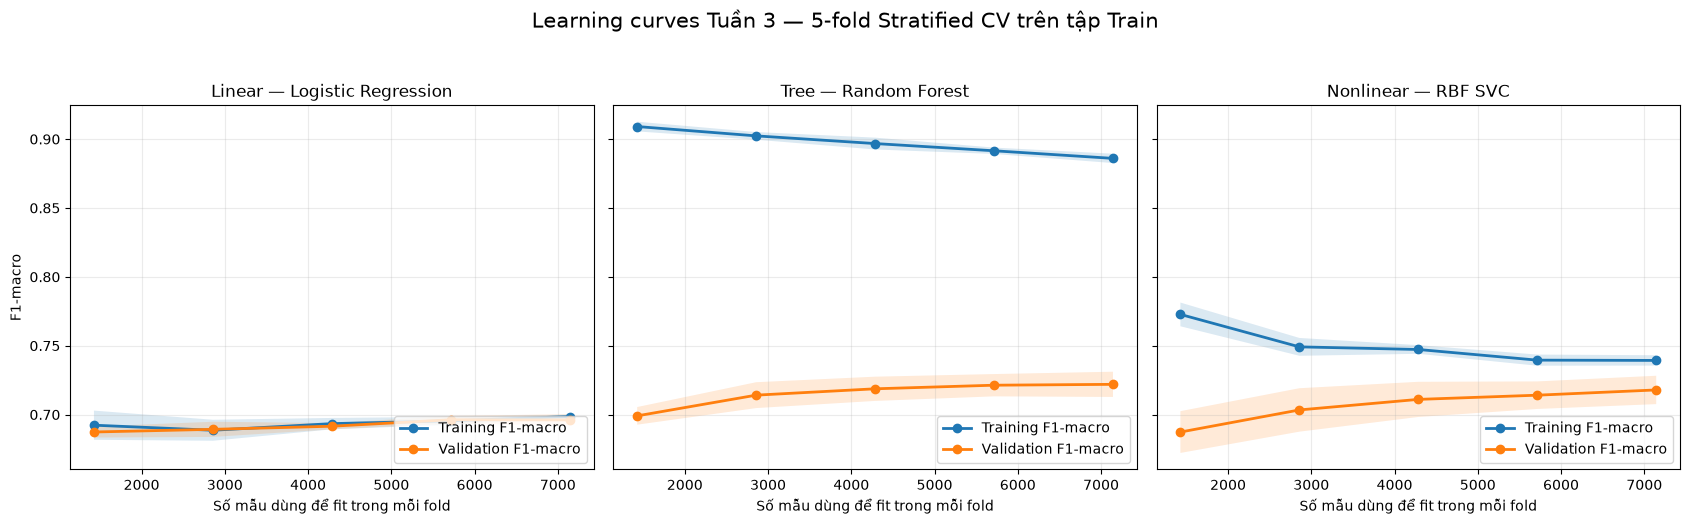

Đã lưu: E:\CodexTemp\btl_week3_reproduction_wcr_k995\05_learning_curves.png


In [6]:
curve_specs = [
    ('Linear — Logistic Regression', best_models['linear']),
    ('Tree — Random Forest', best_models['tree']),
    ('Nonlinear — RBF SVC', best_models['nonlinear']),
]
train_size_fractions = np.linspace(0.2, 1.0, 5)
curve_results = {}
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message=r'.*sklearn.utils.parallel.delayed.*', category=UserWarning)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), sharey=True)
for ax, (label, estimator) in zip(axes, curve_specs):
    sizes, train_scores, validation_scores = learning_curve(
        clone(estimator),
        X_train,
        y_train,
        train_sizes=train_size_fractions,
        cv=cv,
        scoring=PRIMARY_SCORING,
        n_jobs=1,
        shuffle=True,
        random_state=RANDOM_STATE,
        error_score='raise',
    )
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    validation_mean = validation_scores.mean(axis=1)
    validation_std = validation_scores.std(axis=1)
    curve_results[label] = {
        'train_sizes': sizes,
        'train_mean': train_mean,
        'train_std': train_std,
        'validation_mean': validation_mean,
        'validation_std': validation_std,
    }

    ax.plot(sizes, train_mean, marker='o', linewidth=2, label='Training F1-macro')
    ax.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.16)
    ax.plot(sizes, validation_mean, marker='o', linewidth=2, label='Validation F1-macro')
    ax.fill_between(sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.16)
    ax.set_title(label)
    ax.set_xlabel('Số mẫu dùng để fit trong mỗi fold')
    ax.grid(alpha=0.25)
    ax.legend(loc='lower right')

axes[0].set_ylabel('F1-macro')
fig.suptitle('Learning curves Tuần 3 — 5-fold Stratified CV trên tập Train', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.94))
figure_path = REPRO_DIR / '05_learning_curves.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print(f'Đã lưu: {figure_path}')

# 12–13. Best Hyperparameters và nhận xét Overfitting / Underfitting

In [7]:
curve_summary_rows = []
for label, values in curve_results.items():
    final_train = float(values['train_mean'][-1])
    final_validation = float(values['validation_mean'][-1])
    validation_gain = float(values['validation_mean'][-1] - values['validation_mean'][-2])
    gap = final_train - final_validation
    if gap >= 0.08:
        fit_signal = 'Khoảng cách train–validation lớn: dấu hiệu variance/overfitting.'
    elif gap >= 0.03:
        fit_signal = 'Khoảng cách train–validation vừa: có variance nhưng chưa cực đoan.'
    else:
        fit_signal = 'Hai đường khá gần nhau: variance thấp; mức điểm có thể bị giới hạn bởi bias.'
    if validation_gain >= 0.01:
        data_signal = 'Điểm validation còn tăng rõ ở mốc cuối; thêm dữ liệu có thể hữu ích.'
    elif validation_gain >= 0.003:
        data_signal = 'Điểm validation còn tăng nhẹ; lợi ích của thêm dữ liệu có thể ở mức vừa.'
    else:
        data_signal = 'Điểm validation gần bão hòa ở hai mốc cuối.'
    curve_summary_rows.append({
        'Model family': label,
        'Final train': final_train,
        'Final validation': final_validation,
        'Final gap': gap,
        'Last validation gain': validation_gain,
        'Fit diagnosis': fit_signal,
        'Data diagnosis': data_signal,
    })
curve_summary = pd.DataFrame(curve_summary_rows)
curve_summary_display = curve_summary.copy()
for column in ['Final train', 'Final validation', 'Final gap', 'Last validation gain']:
    curve_summary_display[column] = curve_summary_display[column].round(4)
curve_summary_display

,Model family,Final train,Final validation,Final gap,Last validation gain,Fit diagnosis,Data diagnosis
0,Linear — Logistic Regression,0.6986,0.6961,0.0024,-0.0001,Hai đường khá gần nhau: variance thấp; mức điể...,Điểm validation gần bão hòa ở hai mốc cuối.
1,Tree — Random Forest,0.8860,0.7220,0.1641,0.0006,Khoảng cách train–validation lớn: dấu hiệu var...,Điểm validation gần bão hòa ở hai mốc cuối.
2,Nonlinear — RBF SVC,0.7393,0.7179,0.0214,0.0038,Hai đường khá gần nhau: variance thấp; mức điể...,Điểm validation còn tăng nhẹ; lợi ích của thêm...


In [8]:
def tuned_row(model_name):
    return comparison[(comparison['Model'] == model_name) & (comparison['Configuration'] == 'Tuned')].iloc[0]

linear_row = tuned_row('Logistic Regression')
tree_row = tuned_row('Random Forest')
nonlinear_row = tuned_row('SVC')

best_hyperparameters = {
    'experiment': {
        'primary_scoring': PRIMARY_SCORING,
        'data_scope': 'X_train and y_train only',
        'cv': {'type': 'StratifiedKFold', 'n_splits': 5, 'shuffle': True, 'random_state': RANDOM_STATE},
        'note': 'No held-out test result is included; final champion selection is deferred to Week 4.',
    },
    'linear': {
        'owner': 'Loi',
        'algorithm': 'LogisticRegression',
        'best_params': {'C': 10.0, 'penalty': 'l1'},
        'best_cv_score': float(linear_row['Mean CV score']),
        'cv_std': float(linear_row['CV std']),
        'teammate_reported_best_cv_score': 0.6960,
        'elapsed_seconds': None,
        'elapsed_note': 'Original Grid Search elapsed time was not persisted by the teammate implementation.',
        'artifact': 'models/best_linear_model.pkl',
    },
    'tree': {
        'owner': 'Tri',
        'algorithm': 'RandomForestClassifier',
        'best_params': {'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 10},
        'best_cv_score': float(tree_row['Mean CV score']),
        'cv_std': float(tree_row['CV std']),
        'teammate_reported_best_cv_score': 0.7233,
        'elapsed_seconds': None,
        'elapsed_note': 'Original Grid Search elapsed time was not persisted by the teammate implementation.',
        'artifact': 'models/best_tree_model.pkl',
        'feature_importance_available': bool(hasattr(best_models['tree'], 'feature_importances_')),
    },
    'nonlinear': {
        'owner': 'Danh',
        'algorithm': 'SVC (RBF kernel)',
        'best_params': {'C': 100.0, 'gamma': 0.01, 'kernel': 'rbf'},
        'best_cv_score': float(nonlinear_row['Mean CV score']),
        'cv_std': float(nonlinear_row['CV std']),
        'teammate_reported_best_cv_score': 0.7178,
        'elapsed_seconds': 320.0,
        'elapsed_note': 'Approximate Grid Search time reported by Danh; hardware dependent.',
        'artifact': 'models/best_nonlinear_model.pkl',
    },
}

json_path = REPRO_DIR / 'best_hyperparameters.json'
json_path.write_text(json.dumps(best_hyperparameters, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print(json.dumps(best_hyperparameters, ensure_ascii=False, indent=2))

{
  "experiment": {
    "primary_scoring": "f1_macro",
    "data_scope": "X_train and y_train only",
    "cv": {
      "type": "StratifiedKFold",
      "n_splits": 5,
      "shuffle": true,
      "random_state": 42
    },
    "note": "No held-out test result is included; final champion selection is deferred to Week 4."
  },
  "linear": {
    "owner": "Loi",
    "algorithm": "LogisticRegression",
    "best_params": {
      "C": 10.0,
      "penalty": "l1"
    },
    "best_cv_score": 0.6960373975431392,
    "cv_std": 0.003994977288797795,
    "teammate_reported_best_cv_score": 0.696,
    "elapsed_seconds": null,
    "elapsed_note": "Original Grid Search elapsed time was not persisted by the teammate implementation.",
    "artifact": "models/best_linear_model.pkl"
  },
  "tree": {
    "owner": "Tri",
    "algorithm": "RandomForestClassifier",
    "best_params": {
      "n_estimators": 300,
      "max_depth": 20,
      "min_samples_split": 10
    },
    "best_cv_score": 0.7232786044431585,

In [9]:
def markdown_value(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return 'N/A'
    if isinstance(value, float):
        return f'{value:.4f}'
    if isinstance(value, dict):
        return json.dumps(value, ensure_ascii=False)
    return str(value)

report_table_columns = ['Owner', 'Model', 'Configuration', 'Mean CV score', 'CV std', 'Best parameters', 'Tuning time (s)']
report_table = comparison[report_table_columns]
table_lines = [
    '| ' + ' | '.join(report_table_columns) + ' |',
    '|' + '|'.join(['---'] * len(report_table_columns)) + '|',
]
for _, row in report_table.iterrows():
    table_lines.append('| ' + ' | '.join(markdown_value(row[column]) for column in report_table_columns) + ' |')
comparison_markdown = '\n'.join(table_lines)

curve_lines = []
for _, row in curve_summary.iterrows():
    curve_lines.append(
        f"- {row['Model family']}: train={row['Final train']:.4f}, validation={row['Final validation']:.4f}, "
        f"gap={row['Final gap']:.4f}. {row['Fit diagnosis']} {row['Data diagnosis']}"
    )
curve_markdown = '\n'.join(curve_lines)

strongest = comparison[comparison['Configuration'] == 'Tuned'].sort_values('Mean CV score', ascending=False).iloc[0]
report_content = f'''# Mục 3 — Mô hình & Phương pháp (tích hợp Tuần 3)

## 3.1. Thiết lập thực nghiệm chung

Thực nghiệm dùng 8.929 mẫu và 32 đặc trưng trong X_train cùng y_train. Dữ liệu đầu vào đã được pipeline Tuần 2 mã hóa và scale, không có NaN hoặc vô cùng. Tất cả so sánh dùng StratifiedKFold 5 folds, shuffle=True, random_state=42 và F1-macro. Tập held-out của Tuần 4 được giữ riêng và không tham gia fit, tuning, so sánh, learning curves hoặc lựa chọn ứng viên.

## 3.2. Mô hình tuyến tính — Lợi

Phương pháp và diễn giải chi tiết được giữ tại reports/week3_linear_model_Loi.md. Kết quả được kế thừa gồm Dummy most-frequent 0.3448, Logistic Regression default 0.6990 và cấu hình tuned C=10, L1 đạt 0.6960 theo báo cáo. Artifact là models/best_linear_model.pkl.

## 3.3. Random Forest / Ensemble — Trí

Phương pháp và diễn giải chi tiết được giữ tại reports/week3_tree_model_ensemble_Tri.md. Random Forest default đạt 0.7124; cấu hình tuned gồm n_estimators=300, max_depth=20, min_samples_split=10 đạt 0.7233 theo báo cáo. Artifact là models/best_tree_model.pkl và có feature_importances_.

## 3.4. Nonlinear SVM — Danh

Phương pháp và diễn giải chi tiết được giữ tại reports/week3_nonlinear_model.md. SVC default đạt 0.6960 ± 0.0051; RBF SVC tuned với C=100 và gamma=0.01 đạt 0.7178 ± 0.0104 theo báo cáo. Grid Search 33 cấu hình mất xấp xỉ 320 giây. Artifact là models/best_nonlinear_model.pkl.

## 3.5. So sánh chung trên Cross-Validation

Bảng sau tái tính mean và std bằng cùng splitter trên tập Train. Điểm có thể khác ở chữ số cuối so với báo cáo đã làm tròn. N/A nghĩa là thời gian Grid Search ban đầu không được lưu; không thay bằng 0.

{comparison_markdown}

Ứng viên có điểm CV trung bình cao nhất trong phép so sánh chung là {strongest['Model']} tuned ({strongest['Mean CV score']:.4f}). Đây chỉ là ứng viên CV mạnh nhất; chưa phải champion cuối cùng. Quyết định cuối chờ đánh giá held-out ở Tuần 4.


## 3.6. Learning curves — Nhân

Hình figures/05_learning_curves.png trình bày training và validation F1-macro theo kích thước dữ liệu, dùng đúng 5-fold CV trên tập Train.

{curve_markdown}

Các chẩn đoán trên dựa vào khoảng cách hai đường và thay đổi ở hai mốc dữ liệu cuối; chúng mô tả xu hướng quan sát được, không khẳng định hiệu năng ngoài mẫu trước khi có đánh giá Tuần 4.
'''
report_path = REPRO_DIR / 'week3_model_integration_Nhan.md'
report_path.write_text(report_content, encoding='utf-8')
print(f'Đã lưu: {report_path}')

Đã lưu: E:\CodexTemp\btl_week3_reproduction_wcr_k995\week3_model_integration_Nhan.md


# 14. Kết luận Week 3

Ba họ mô hình đã được đặt trong cùng quy ước CV và F1-macro. Notebook chỉ xác định ứng viên CV mạnh nhất tại thời điểm này; không tuyên bố champion cuối cùng và không tạo champion_model.pkl. Đánh giá held-out thuộc phạm vi Tuần 4.